# Distributed and Secure Kernel-Based Quantum Machine Learning — Reproduction

Paper: A. Swaminathan and M. Akgün, *Transactions on Machine Learning Research* (2025), [OpenReview](https://openreview.net/forum?id=3jdI0aEW3k); we read [arXiv 2408.10265](https://arxiv.org/abs/2408.10265) v3. Authors' code: [mdppml/distributed-secure-kernel-based-QML](https://github.com/mdppml/distributed-secure-kernel-based-QML), archived on [Zenodo](https://doi.org/10.5281/zenodo.18743937). Setup, data and deviations are in `README.md`; details in `docs/`.

## Summary

- **The paper:** two data holders can obtain a quantum kernel between their private samples without sending their data: teleportation moves the encoded states to a server, whose swap test computes the kernel (claim 1), with accuracy comparable to centralised computation (claim 2). The paper validates this as a proof of concept, in simulation and with amplitude encoding only (Section 1).
- **The reproduction:** the proof of concept holds. Shot-by-shot simulations of the authors' circuits follow the swap-test law, distributed or centralised (Section 2), and Table 1 is reproduced, with 12 of 15 cells within the paper's fold std (Section 3).
- **MerLin:** the swap test translates exactly to photonics (register-wise Hong–Ou–Mandel interference: same law, same accuracies within 2 σ); teleportation does not translate deterministically to linear optics (Section 6).
- **Limits:**
  - "Comparable to classical" does not hold against a fair baseline: without the leaks of the authors' protocol, a tuned classical SVM is higher on every dataset, and on Framingham the quantum kernel only predicts the majority class (Section 5).
  - Security is argued, not tested: all parties run as one simulated circuit, and the server receives about 1,024 copies of each encoded state per kernel entry (README, "Limitations").

**Runtime.** About 75 s on a laptop CPU. Every live run below is checked against the stored sweeps; the tables and figures come from those sweeps (`results/`, regenerated by `utils/paper_layout_results.py`).

In [1]:
import contextlib
import io
import json
import logging
import sys
import tempfile
import time
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display
from scipy import stats

PAPER_DIR = Path.cwd()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError("Start the notebook from papers/distributed_secure_kernels/")
sys.path[:0] = [str(PAPER_DIR.parent), str(PAPER_DIR.parents[1])]

from distributed_secure_kernels.lib.data import build_dataset  # noqa: E402
from distributed_secure_kernels.lib.photonic_merlin import (  # noqa: E402
    PhotonicSwapTest,
    encode_registers,
    register_modes,
)
from distributed_secure_kernels.lib.protocol import (  # noqa: E402
    centralised_circuit,
    distributed_circuit,
    independent_seed,
    run_ancilla_zeros,
)
from distributed_secure_kernels.lib.runner import train_and_evaluate  # noqa: E402
from runtime_lib.config import deep_update, load_config  # noqa: E402
from runtime_lib.dtypes import resolve_config_dtypes  # noqa: E402
from runtime_lib.seed import seed_everything  # noqa: E402

logging.disable(logging.INFO)  # the runs still write their own run.log files
SEEDS = [0, 1, 2, 3, 4]
RESULTS = PAPER_DIR / "results"
STORED = json.loads((RESULTS / "sweep_results.json").read_text())
LIVE_DIR = Path(tempfile.mkdtemp(prefix="dsk_notebook_"))
NOTEBOOK_START = time.perf_counter()


def load_cfg(config_name: str, seed: int) -> dict:
    # Same merge as the shared runtime: defaults.json, then the named config.
    cfg = deep_update(
        load_config(PAPER_DIR / "configs" / "defaults.json"),
        load_config(PAPER_DIR / "configs" / config_name),
    )
    cfg["seed"] = seed
    return resolve_config_dtypes(cfg)


def run_live(config_name: str) -> dict[int, dict]:
    # One run per seed through lib.runner.train_and_evaluate; returns {seed: metrics}.
    out = {}
    for seed in SEEDS:
        seed_everything(seed)
        run_dir = LIVE_DIR / f"{Path(config_name).stem}_seed{seed}"
        run_dir.mkdir(parents=True, exist_ok=True)
        with contextlib.redirect_stderr(io.StringIO()):
            train_and_evaluate(load_cfg(config_name, seed), run_dir)
        out[seed] = json.loads((run_dir / "metrics.json").read_text())
    return out


def fold_mean(metrics: dict, method: str, model: str, metric: str) -> float:
    # 5-fold mean of one method and model in one run's metrics.json.
    outcome = metrics["methods"][method]
    if model == "kernel_svm":
        summary = outcome["kernel_svm"]
    elif model == "kernel_pca_best_on_test_folds":
        summary = outcome["kernel_pca"]["best_on_test_folds"]
    else:  # kernel_pca_nested_cv
        summary = outcome["kernel_pca"]
    return summary[metric]["mean"]


def check_against_stored(runs: dict, sweep: str, candidate: str, pairs) -> float:
    # Largest |live - stored| over the (method, model) pairs, seeds and both metrics.
    stored = {
        (row["method"], row["model"]): row
        for row in STORED[sweep]["rows"]
        if row["candidate"] == candidate
    }
    gaps = [
        abs(
            fold_mean(runs[seed], method, model, metric)
            - stored[(method, model)][metric]["per_seed"][str(seed)]
        )
        for method, model in pairs
        for metric in ("accuracy", "balanced_accuracy")
        for seed in SEEDS
    ]
    return max(gaps)


def show(name: str, width: int = 640) -> None:
    # Display a stored table (.md) or figure (.png) from results/.
    path = RESULTS / name
    if path.suffix == ".md":
        display(Markdown(path.read_text()))
    else:
        display(Image(filename=str(path), width=width))

## 1. The protocol

Each data holder amplitude-encodes its sample; teleportation moves the two states to a server, whose swap test estimates the kernel; a classical kernel SVM or kernel PCA learns from the kernel matrix (diagram: README, "Original Paper").

Simulating every kernel entry shot by shot, as the authors do, is too costly for us. Each shot reads 0 with a known probability, p₀ = ½ + ½|⟨a|b⟩|² (App. A), so we draw the 1,024 shots directly from that law: same kernel, same shot noise (README, "Simulation setup"; details in `docs/swap_test_kernel.md`).

## 2. Claim 1: the distributed protocol computes the same kernel as a centralised swap test

We run the authors' circuits shot by shot on Qiskit Aer for 20 random pairs of 2-qubit states and compare the counts with the binomial law (χ² test: a small p would mean that a circuit does not follow the law).

In [2]:
rng = np.random.default_rng(2024)
shots, pairs = 1024, 20
p0, zeros = [], {"distributed": [], "centralised": []}
for index in range(pairs):
    a, b = rng.normal(size=4), rng.normal(size=4)
    a, b = a / np.linalg.norm(a), b / np.linalg.norm(b)
    p0.append(0.5 + 0.5 * (a @ b) ** 2)
    zeros["distributed"].append(
        run_ancilla_zeros(distributed_circuit(a, b), shots, 0.0, independent_seed(1, index))
    )
    zeros["centralised"].append(
        run_ancilla_zeros(centralised_circuit(a, b), shots, 0.0, independent_seed(2, index))
    )
p0 = np.array(p0)
for circuit, counts in zeros.items():
    chi2 = float(np.sum((np.array(counts) - shots * p0) ** 2 / (shots * p0 * (1 - p0))))
    print(f"{circuit:12s}: chi2 = {chi2:5.1f} on {pairs} dof, p = {stats.chi2.sf(chi2, pairs):.2f}")

distributed : chi2 =  20.7 on 20 dof, p = 0.41
centralised : chi2 =  29.3 on 20 dof, p = 0.08


The stored check (30 pairs, 2 and 4 qubits per party) gives the same picture: every point lies on the diagonal, nearly all inside the ±2 standard-deviation band.

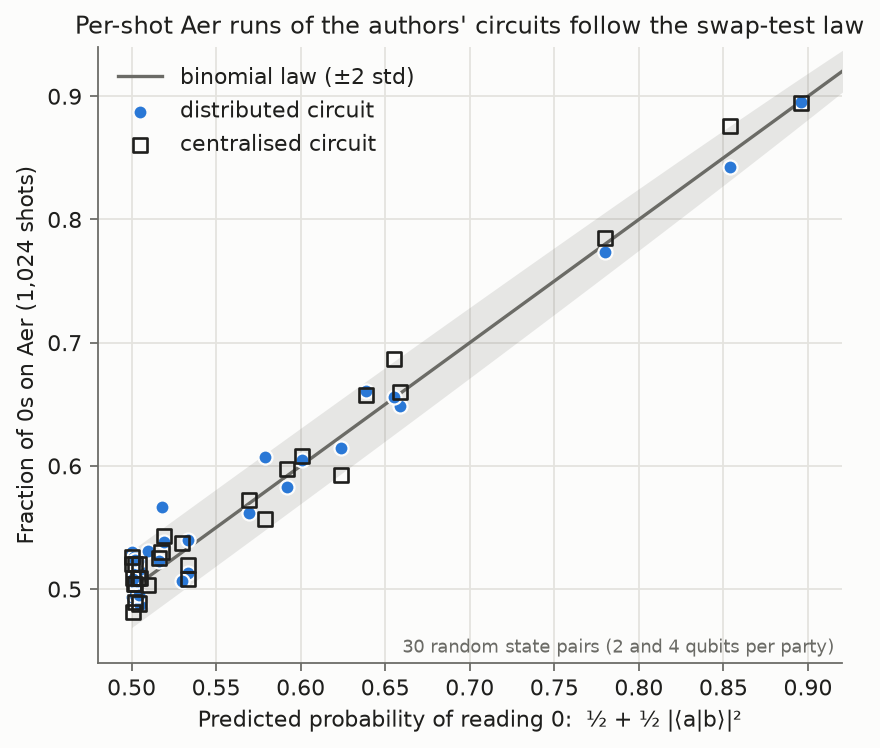

In [3]:
show("protocol_check.png", width=420)

## 3. Claim 2: Table 1 is reproduced

Paper protocol, accuracy. Wine and Parkinson's run live for 5 seeds and must match the stored sweeps; Framingham (about 50 s per seed) is loaded. kSVM: kernel SVM; kPCA: kernel PCA followed by a linear SVM. Paper: one run, ± fold std; ours: mean ± std over seeds 0–4.

In [4]:
started = time.perf_counter()
columns = ("classical_linear", "quantum_centralised", "quantum_distributed")
models = {"wine": ["kernel_svm"], "parkinsons": ["kernel_svm", "kernel_pca_best_on_test_folds"]}
for name in ("wine", "parkinsons"):
    runs = run_live(f"accuracy_{name}_original.json")
    pairs = [(method, model) for method in columns for model in models[name]]
    gap = check_against_stored(runs, "table1_original", f"accuracy_{name}_original", pairs)
    print(f"{name}: largest |live - stored| = {gap:.1e}")
print(f"10 live runs in {time.perf_counter() - started:.0f} s")
show("table1.md")

wine: largest |live - stored| = 0.0e+00


parkinsons: largest |live - stored| = 0.0e+00
10 live runs in 1 s


| Dataset | Method | | Centralised classical | Centralised quantum | Distributed quantum |
|---|---|---|---:|---:|---:|
| Wine | kSVM | paper | 0.986 ± 0.017 | 0.880 | 0.887 ± 0.026 |
| | | ours | 0.986 ± 0.000 | 0.907 ± 0.019 | 0.896 ± 0.009 |
| Parkinson's | kSVM | paper | 0.820 ± 0.064 | 0.787 | 0.798 ± 0.080 |
| | | ours | 0.805 ± 0.013 | 0.772 ± 0.021 | 0.756 ± 0.035 |
|  | kPCA | paper | 0.787 ± 0.072 | 0.745 | 0.766 ± 0.074 |
| | | ours | 0.812 ± 0.005 | 0.703 ± 0.045 | 0.700 ± 0.047 |
| Framingham | kSVM | paper | 0.679 ± 0.011 | 0.631 | 0.634 ± 0.014 |
| | | ours | 0.689 ± 0.003 | 0.634 ± 0.009 | 0.639 ± 0.010 |
|  | kPCA | paper | 0.679 ± 0.009 | 0.625 | 0.642 ± 0.009 |
| | | ours | 0.682 ± 0.004 | 0.625 ± 0.000 | 0.625 ± 0.000 |


12 of 15 cells fall within the paper's fold std; distributed and centralised quantum differ only by shot noise.

## 4. Side results: Fig. 3 and Fig. 4

Paper protocol, accuracy. Fig. 4 (Digits, 100 samples) runs live; Fig. 3 (noise, 40–320 s per seed) is loaded. Diamonds: the authors' values (their logs for Fig. 3).

Digits: largest |live - stored| = 0.0e+00


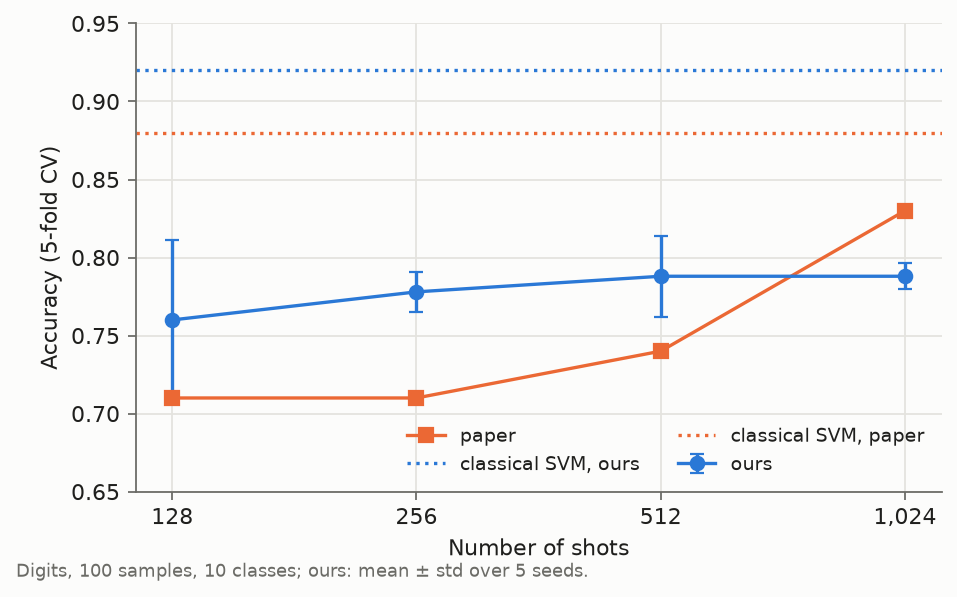

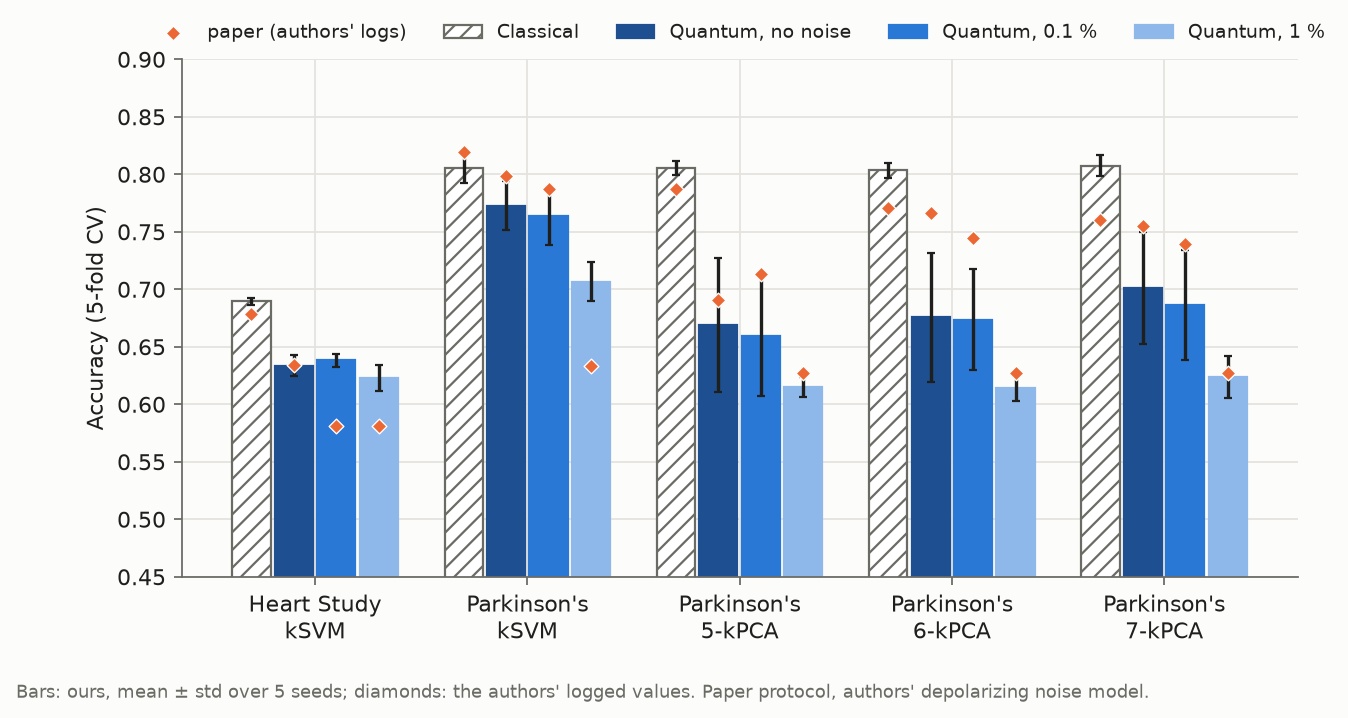

In [5]:
runs = run_live("shots_digits_original.json")
pairs = [(f"quantum_distributed_{s}_shots", "kernel_svm") for s in (128, 256, 512, 1024)]
gap = check_against_stored(runs, "shots_original", "shots_digits_original", pairs)
print(f"Digits: largest |live - stored| = {gap:.1e}")
show("fig4.png", width=480)
show("fig3.png")

**Fig. 4:** our accuracy rises little with shots (0.760 at 128 shots, 0.788 at 1,024), less than the paper's (0.71 to 0.83); our steps are smaller than the seed spread at 128 shots.

**Fig. 3:** noise lowers accuracy in both, but less in ours: at 1 % the Parkinson's kernel SVM falls to 0.707, against 0.633 in the authors' logs. The size of the drop depends on whether state preparation is noisy, which the paper does not state; noise is not one of our messages.

## 5. Limit: "comparable to classical" does not hold against a fair baseline

Corrected protocol: everything fitted (oversampling, scaler, kernel PCA, C and the component count) uses the training folds only (`docs/protocols.md`). Balanced accuracy; classical columns: linear and RBF SVMs, tuned by inner cross-validation. Wine and Parkinson's run live.

In [6]:
started = time.perf_counter()
for name in ("wine", "parkinsons"):
    corrected = run_live(f"accuracy_{name}_corrected.json")
    fair = run_live(f"accuracy_{name}_fair_classical.json")
    gaps = (
        check_against_stored(
            corrected,
            "table1_corrected",
            f"accuracy_{name}_corrected",
            [(m, "kernel_svm") for m in columns],
        ),
        check_against_stored(
            fair, "fair_comparison", f"accuracy_{name}_fair_classical", [("tuned_rbf", "kernel_svm")]
        ),
    )
    print(f"{name}: largest |live - stored| = {max(gaps):.1e}")
print(f"20 live runs in {time.perf_counter() - started:.0f} s")
show("table1_bis.md")

wine: largest |live - stored| = 0.0e+00


parkinsons: largest |live - stored| = 0.0e+00
20 live runs in 48 s


| Dataset | Method | Centralised classical | Centralised quantum | Distributed quantum | RBF SVM |
|---|---|---:|---:|---:|---:|
| Wine | kSVM | 0.983 ± 0.000 | 0.896 ± 0.014 | 0.895 ± 0.010 | 0.983 ± 0.000 |
| Parkinson's | kSVM | 0.751 ± 0.016 | 0.622 ± 0.038 | 0.623 ± 0.034 | 0.913 ± 0.008 |
|  | kPCA | 0.745 ± 0.012 | 0.582 ± 0.021 | 0.591 ± 0.039 | 0.698 ± 0.026 |
| Framingham | kSVM | 0.629 ± 0.001 | 0.501 ± 0.001 | 0.501 ± 0.001 | 0.512 ± 0.004 |
|  | kPCA | 0.547 ± 0.006 | 0.500 ± 0.000 | 0.500 ± 0.000 | 0.511 ± 0.004 |


Without the leaks of the authors' protocol, a classical SVM is higher beyond 2 σ of the seed spread on every dataset, and on Framingham the quantum kernel only predicts the majority class (balanced accuracy 0.50). Even with the authors' protocol, the linear SVM is higher beyond 2 σ in 4 of the 5 Table 1 cells.

## 6. MerLin: the swap test translates exactly to photonics

Only the encoding and the swap test are translated; teleportation has no deterministic linear-optics counterpart (README, "Photonic adaptation"). Each sample is amplitude-encoded on 2 photons in m modes, and register-wise Hong–Ou–Mandel interference with a parity readout plays the swap test. First, the photonic probability against the swap-test law on random Wine pairs:

In [7]:
wine = build_dataset(load_cfg("accuracy_wine_original.json", seed=0), "train")
modes = register_modes(wine.features.shape[1])
registers = encode_registers(wine.features, modes)
rng = np.random.default_rng(3)
left, right = rng.integers(0, len(registers), 300), rng.integers(0, len(registers), 300)
photonic = PhotonicSwapTest(modes).even_probability(registers[left], registers[right])
expected = 0.5 + 0.5 * np.sum(registers[left] * registers[right], axis=1) ** 2
print(f"4 photons on {2 * modes} modes; 300 random pairs:")
print(f"max |P(even) - (1/2 + 1/2 |<a|b>|^2)| = {np.max(np.abs(photonic - expected)):.1e}")

4 photons on 12 modes; 300 random pairs:
max |P(even) - (1/2 + 1/2 |<a|b>|^2)| = 6.9e-09


Then the Table 1 settings (paper protocol, accuracy; Wine and Parkinson's live) and the Fig. 4 settings (stored):

wine: largest |live - stored| = 0.0e+00


parkinsons: largest |live - stored| = 0.0e+00
10 live MerLin runs in 18 s


| Dataset | Method | Centralised quantum | Distributed quantum | MerLin photonic |
|---|---|---:|---:|---:|
| Wine | kSVM | 0.907 ± 0.019 | 0.896 ± 0.009 | 0.909 ± 0.013 |
| Parkinson's | kSVM | 0.772 ± 0.021 | 0.756 ± 0.035 | 0.764 ± 0.019 |
|  | kPCA | 0.703 ± 0.045 | 0.700 ± 0.047 | 0.706 ± 0.045 |
| Framingham | kSVM | 0.634 ± 0.009 | 0.639 ± 0.010 | 0.632 ± 0.011 |
|  | kPCA | 0.625 ± 0.000 | 0.625 ± 0.000 | 0.625 ± 0.000 |


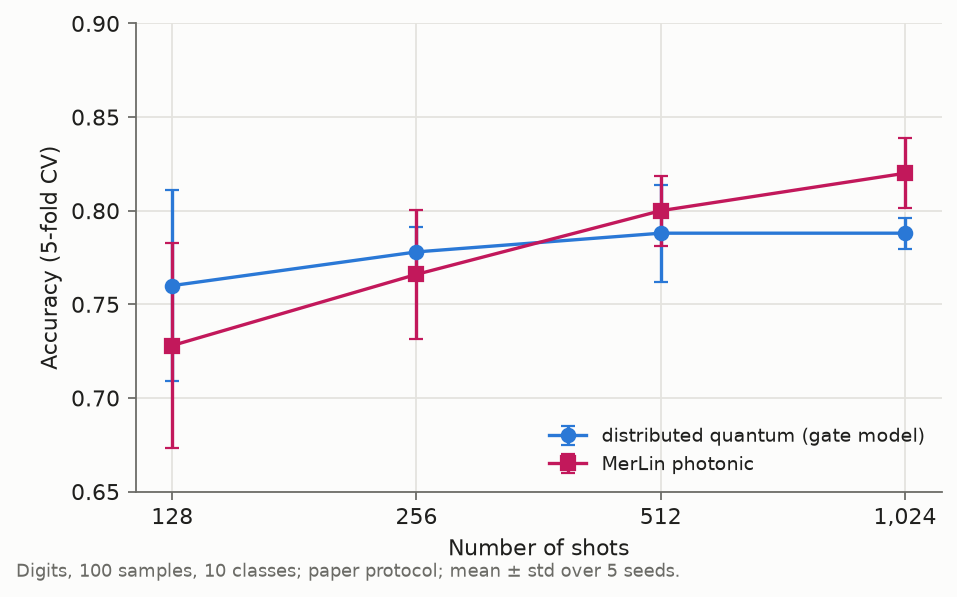

In [8]:
started = time.perf_counter()
for name in ("wine", "parkinsons"):
    runs = run_live(f"accuracy_{name}_merlin.json")
    gap = check_against_stored(
        runs,
        "merlin_original",
        f"accuracy_{name}_merlin",
        [("merlin_photonic_swap_test", model) for model in models[name]],
    )
    print(f"{name}: largest |live - stored| = {gap:.1e}")
print(f"10 live MerLin runs in {time.perf_counter() - started:.0f} s")
show("table1_merlin.md")
show("fig4_merlin.png", width=480)

The photonic kernel matches the distributed gate-model kernel within 2 σ of the seed spread in every cell. In the Fig. 4 settings the two agree within 2 σ at 128, 256 and 512 shots; at 1,024 shots MerLin is higher by 0.032, just above the 2 σ tolerance (0.029); the two kernels follow the same law, so this comes from independent shot draws.

## 7. Conclusion

- **The paper:** two data holders can obtain a quantum kernel between their private samples without sending their data: teleportation moves the encoded states to a server, whose swap test computes the kernel (claim 1), with accuracy comparable to centralised computation (claim 2). The paper validates this as a proof of concept, in simulation and with amplitude encoding only (Section 1).
- **The reproduction:** the proof of concept holds. Shot-by-shot simulations of the authors' circuits follow the swap-test law, distributed or centralised (Section 2), and Table 1 is reproduced, with 12 of 15 cells within the paper's fold std (Section 3).
- **MerLin:** the swap test translates exactly to photonics (register-wise Hong–Ou–Mandel interference: same law, same accuracies within 2 σ); teleportation does not translate deterministically to linear optics (Section 6).
- **Limits:**
  - "Comparable to classical" does not hold against a fair baseline: without the leaks of the authors' protocol, a tuned classical SVM is higher on every dataset, and on Framingham the quantum kernel only predicts the majority class (Section 5).
  - Security is argued, not tested: all parties run as one simulated circuit, and the server receives about 1,024 copies of each encoded state per kernel entry (README, "Limitations").

In [9]:
print(f"Notebook executed in {time.perf_counter() - NOTEBOOK_START:.0f} s")

Notebook executed in 69 s
